# Senim — English → Kazakh translation that warns when not to trust it

Veritas AI Hackathon 2026 · Track AI + Languages · based on brief 4.4.2 *Translation quality test*.

**Run on Google Colab with a T4 GPU** (Runtime → Change runtime type → T4 GPU), then Runtime → Run all.
Needs a Colab secret `HF_TOKEN` (FLORES+ is a gated dataset: accept its terms on Hugging Face first).

Steps:
1. Load 150 FLORES+ devtest sentences (English + Kazakh/Russian/French references).
2. Translate with `facebook/nllb-200-distilled-600M`, score chrF per language, compare with a "leave it in English" baseline.
3. Show the 5 worst Kazakh translations.
4. Translate our own set (`data/own_set.csv`: medicine leaflets and school letters).
5. Trust check: numbers / dosages / dates + back-translation chrF.
6. With quality ratings (`data/ratings.csv`: human ratings by the author, plus an LLM judge for comparison): correlation with chrF, and how many bad translations the trust check catches vs. "always trust".

*This project is a prototype and is not medical advice.*

In [4]:
# Setup: get the repo (data + shared code) and install the one missing library.
import os, sys, subprocess
REPO_URL = "https://github.com/arturbaimuratov1-sys/senim"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("/content/senim"):
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/senim"], check=True)
    else:
        # results/ in the Colab copy is regenerated by every run, so local changes there can be dropped
        subprocess.run(["git", "-C", "/content/senim", "fetch", "-q", "origin"], check=True)
        subprocess.run(["git", "-C", "/content/senim", "reset", "-q", "--hard", "origin/main"], check=True)
    os.chdir("/content/senim")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sacrebleu", "sentence-transformers"], check=True)
sys.path.insert(0, os.getcwd())
os.makedirs("results", exist_ok=True)

import torch
print("cwd:", os.getcwd())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU will be slow)")

cwd: /content/senim
GPU: Tesla T4


In [5]:
# Hugging Face token from the Colab secret HF_TOKEN (never printed or saved).
HF_TOKEN = None
if IN_COLAB:
    from google.colab import userdata
    try:
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception as e:
        print("Could not read the HF_TOKEN secret:", type(e).__name__)
else:
    HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN:
    os.environ["HF_TOKEN"] = HF_TOKEN
print("HF token available:", bool(HF_TOKEN))

HF token available: True


## 1. FLORES+ devtest: 150 sentences

In [6]:
import numpy as np, pandas as pd
from datasets import load_dataset

DATASET = "openlanguagedata/flores_plus"
LANGS = {"kaz_Cyrl": "Kazakh", "rus_Cyrl": "Russian", "fra_Latn": "French"}
N = 150
SEED = 42

def load_lang(code):
    ds = load_dataset(DATASET, code, split="devtest", token=HF_TOKEN)
    return pd.DataFrame({"id": ds["id"], code: ds["text"]})

flores = load_lang("eng_Latn")
for code_ in LANGS:
    flores = flores.merge(load_lang(code_), on="id")
print("devtest sentences with all 4 languages:", len(flores))

rng = np.random.default_rng(SEED)
sample_idx = np.sort(rng.choice(len(flores), size=N, replace=False))
flores = flores.iloc[sample_idx].reset_index(drop=True)
flores.head(3)

Resolving data files:   0%|          | 0/233 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

eng_Latn.jsonl:   0%|          | 0.00/423k [00:00<?, ?B/s]

eng_Latn.jsonl:   0%|          | 0.00/440k [00:00<?, ?B/s]

Generating dev split: 0 examples [00:00, ? examples/s]

Generating devtest split: 0 examples [00:00, ? examples/s]

... (16 outputs left out)

Generating dev split: 0 examples [00:00, ? examples/s]

Generating devtest split: 0 examples [00:00, ? examples/s]

devtest sentences with all 4 languages: 1012


,id,eng_Latn,kaz_Cyrl,rus_Cyrl,fra_Latn
0,7,Siminoff said sales boosted after his 2013 app...,"Симиновтың айтуынша, 2013 жылы оның Shark Tank...","Симинофф сказал, что продажи выросли после его...",M. Siminoff a déclaré que les ventes ont augme...
1,30,Because the dinosaur feathers do not have a we...,Динозавр қауырсынында рахис деп аталатын жақсы...,Так как у перьев динозавров отсутствует хорошо...,Étant donné que les plumes de dinosaure n'ont ...
2,35,Police said they suspect an alleged Daesh (ISI...,Полиция болжалды Даеш (ISIL) жауынгері шабуылғ...,"Полиция заявила, что в совершении нападения по...",La police a déclaré soupçonner un militant pré...


## 2. Translate with NLLB-200 (600M distilled)

In [7]:
import time, importlib, senim
importlib.reload(senim)  # pick up the latest senim.py even if the runtime was not restarted
t0 = time.time()
first = senim.translate([flores.loc[0, "eng_Latn"]], "eng_Latn", "kaz_Cyrl")[0]
print("EN:", flores.loc[0, "eng_Latn"])
print("KK (NLLB):", first)
print("KK (reference):", flores.loc[0, "kaz_Cyrl"])
print(f"model load + first sentence: {time.time() - t0:.1f}s")

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (5 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.46GB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

EN: Siminoff said sales boosted after his 2013 appearance in a Shark Tank episode where the show panel declined funding the startup.
KK (NLLB): Симинофтың айтуынша, оның 2013 жылы "Шарк танк" эпизодында пайда болғаннан кейін сату көтерілді, онда шоу панелі стартапты қаржыландырудан бас тартты.
KK (reference): Симиновтың айтуынша, 2013 жылы оның Shark Tank шоуының эпизодында түскеннен кейін сатылымдар айтарлықтай өсті. Ол эпизодта шоудың талқылау тобы оны стартабын қаржыландырудан бас тартқан еді.
model load + first sentence: 73.7s


In [8]:
t0 = time.time()
for code_ in LANGS:
    flores[f"mt_{code_}"] = senim.translate(flores["eng_Latn"].tolist(), "eng_Latn", code_)
    print(f"{LANGS[code_]}: done ({time.time() - t0:.0f}s)")

Kazakh: done (15s)
Russian: done (28s)
French: done (42s)


## 3. chrF per language vs. the "no translation" baseline

Baseline = hand the reader the English text unchanged. chrF counts overlapping character n-grams with the human reference (0–100).

In [9]:
import sacrebleu
rows = []
for code_, name in LANGS.items():
    refs = flores[code_].tolist()
    mt = sacrebleu.corpus_chrf(flores[f"mt_{code_}"].tolist(), [refs]).score
    base = sacrebleu.corpus_chrf(flores["eng_Latn"].tolist(), [refs]).score
    rows.append({"language": name, "code": code_, "n": len(refs),
                 "chrF_NLLB": round(mt, 1), "chrF_baseline_english": round(base, 1)})
chrf_table = pd.DataFrame(rows)
chrf_table.to_csv("results/chrf_by_language.csv", index=False)
chrf_table

,language,code,n,chrF_NLLB,chrF_baseline_english
0,Kazakh,kaz_Cyrl,150,52.1,1.4
1,Russian,rus_Cyrl,150,56.0,1.0
2,French,fra_Latn,150,69.2,25.5


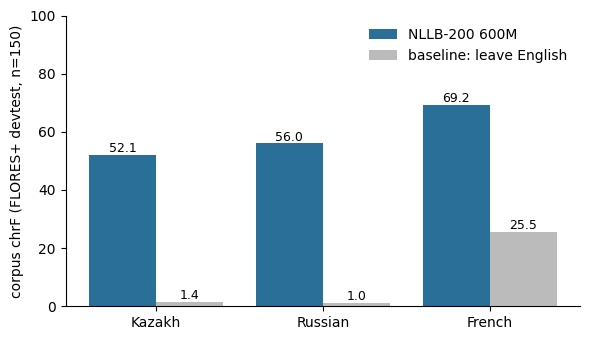

In [10]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 3.5))
x = np.arange(len(chrf_table))
ax.bar(x - 0.2, chrf_table["chrF_NLLB"], 0.4, label="NLLB-200 600M", color="#2a6f97")
ax.bar(x + 0.2, chrf_table["chrF_baseline_english"], 0.4, label="baseline: leave English", color="#bbbbbb")
for i, r in chrf_table.iterrows():
    ax.text(i - 0.2, r["chrF_NLLB"] + 1, f'{r["chrF_NLLB"]:.1f}', ha="center", fontsize=9)
    ax.text(i + 0.2, r["chrF_baseline_english"] + 1, f'{r["chrF_baseline_english"]:.1f}', ha="center", fontsize=9)
ax.set_xticks(x, chrf_table["language"])
ax.set_ylabel("corpus chrF (FLORES+ devtest, n=150)")
ax.set_ylim(0, 100)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("results/chrf_by_language.png", dpi=150)
plt.show()

## 4. Five worst Kazakh translations (sentence chrF)

In [11]:
flores["chrf_kaz"] = [senim.sentence_chrf(h, r) for h, r in zip(flores["mt_kaz_Cyrl"], flores["kaz_Cyrl"])]
worst = flores.nsmallest(5, "chrf_kaz")[["id", "eng_Latn", "kaz_Cyrl", "mt_kaz_Cyrl", "chrf_kaz"]]
worst = worst.rename(columns={"eng_Latn": "source_en", "kaz_Cyrl": "reference_kk", "mt_kaz_Cyrl": "nllb_kk"})
worst.to_csv("results/worst5_kaz.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(worst)

,id,source_en,reference_kk,nllb_kk,chrf_kaz
80,569,"Through the night between 150 and 200 copies were made, now known as ""Dunlap broadsides"".","Бір түн ішінде 150-ден 200-ге дейін көшірмелер жасалып, олар қазір «Dunlap broadsides» ретінде белгілі.","Түн бойы 150 - 200 дана жасалды, қазір ""Дунлап еншілері"" деп аталады.",16.703825
25,177,"The final score was a one-point victory, 21 to 20, ending the All Blacks' 15 game winning streak.","Қорытынды есеп 21-20 болып, бір ұпайлық айырмашылық болды, сонымен қатар ""All Blacks"" 15 ойындық жеңіз сериясын аяқтады.","Соңғы ұпай - бір ұпай жеңісі, 21 - 20, ""Блэкс"" командасының 15 ойын жеңіске жетті.",18.992692
38,302,"Around 60 cases of malfunctioning iPods overheating have been reported, causing a total of six fires and leaving four people with minor burns.","60-қа жуық iPod қызып кету жағдайлары хабарланған, олардың алтауы өртке және төртеуі жеңіл күйік алу жағдайларына себеп болған.","Айфонның жұмыс істемейтіндігінен шамамен 60 жағдай тіркелді, бұл жалпы алғанда алты өртке әкеліп соқты, ал төрт адам аз күйді.",20.985328
98,685,Sharing a field trip virtually is also a great way to reflect a on a trip and share experiences with future classes.,Виртуалды түрде экскурсияны көрсету де экскурсия туралы пікір жинау және келешек сабақтарда тәжірибемен алмасу үшін керемет мүмкіндік.,"Сондай-ақ, іссапарды іс жүзінде бөлісу - сапар туралы ой жүгіртудің және болашақ сыныптармен тәжірибелерді бөлісудің тамаша тәсілі.",22.760427
120,801,"Some venues offer alcoholic beverages on the house. However, drunkenness impairs judgement, and all good gamblers know the importance of staying sober.","Кейбір жерлерде үйде алкогольдік сусындар ұсынылады. Дегенмен, мас болу ойлау қабілетін нашарлатады және барлық жақсы құмар ойыншылар мас емес болудың маңыздылығын біледі.",Кейбір ойын орындарында үйде алкогольді ішімдіктер ұсынылады.,24.518493


## 5. Back-translation on FLORES (no human needed)

Translate NLLB's Kazakh back to English and compare with the English source (chrF).
If this reference-free score tracks the reference-based score, it is a usable warning signal when no reference exists.

Spearman(back-translation chrF, reference chrF) on 150 FLORES sentences: rho=0.30, p=1.9e-04
FLORES sentences flagged by hard checks: 6


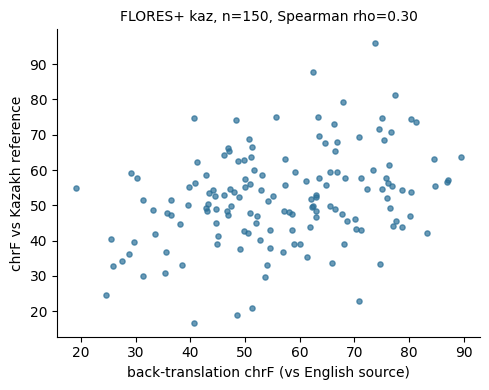

In [12]:
from scipy.stats import spearmanr, pearsonr
flores["back_en"] = senim.translate(flores["mt_kaz_Cyrl"].tolist(), "kaz_Cyrl", "eng_Latn")
flores["bt_chrf"] = [senim.sentence_chrf(b, s) for b, s in zip(flores["back_en"], flores["eng_Latn"])]
flores["hard_check_reasons"] = ["; ".join(senim.hard_checks(s, t)) for s, t in zip(flores["eng_Latn"], flores["mt_kaz_Cyrl"])]
rho, p = spearmanr(flores["bt_chrf"], flores["chrf_kaz"])
print(f"Spearman(back-translation chrF, reference chrF) on {len(flores)} FLORES sentences: rho={rho:.2f}, p={p:.1e}")
print("FLORES sentences flagged by hard checks:", (flores["hard_check_reasons"] != "").sum())
flores.to_csv("results/flores_translations.csv", index=False)

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(flores["bt_chrf"], flores["chrf_kaz"], s=14, alpha=0.7, color="#2a6f97")
ax.set_xlabel("back-translation chrF (vs English source)")
ax.set_ylabel("chrF vs Kazakh reference")
ax.set_title(f"FLORES+ kaz, n={len(flores)}, Spearman rho={rho:.2f}", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("results/bt_vs_reference_chrf.png", dpi=150); plt.show()

## 6. Our own set: medicine leaflets and school letters

`data/own_set.csv` was written by the project author (columns `id, text_en, type`).

In [13]:
own = pd.read_csv("data/own_set.csv", dtype=str).fillna("")
own = own[own["text_en"].str.strip() != ""].reset_index(drop=True)
print("own sentences:", len(own), dict(own["type"].value_counts()) if len(own) else {})
if len(own):
    own["mt_kaz"] = senim.translate(own["text_en"].tolist(), "eng_Latn", "kaz_Cyrl")
    own["back_en"] = senim.translate(own["mt_kaz"].tolist(), "kaz_Cyrl", "eng_Latn")
    own["bt_chrf"] = [senim.sentence_chrf(b, s) for b, s in zip(own["back_en"], own["text_en"])]
    own["hard_check_reasons"] = ["; ".join(senim.hard_checks(s, t)) for s, t in zip(own["text_en"], own["mt_kaz"])]
    own.to_csv("results/own_set_translations.csv", index=False)
    with pd.option_context("display.max_colwidth", 80):
        display(own[["id", "type", "text_en", "mt_kaz", "bt_chrf", "hard_check_reasons"]].head(10))
else:
    print("data/own_set.csv is empty -> skipped (fill it in and re-run).")

own sentences: 50 {'medicine': np.int64(25), 'school': np.int64(25)}


,id,type,text_en,mt_kaz,bt_chrf,hard_check_reasons
0,1,medicine,Adults should take one 500 mg tablet twice a day with a full glass of water,Ересектер күніне екі рет бір 500 мг таблетканы толы стакан сумен бірге қабыл...,99.653080,
1,2,medicine,Give children aged 6 to 12 years 5 ml of this medicine every 8 hours,6 жастан 12 жасқа дейінгі балаларға 8 сағат сайын 5 мл препаратты беріңіз.,67.444711,
2,3,medicine,Take this medicine after breakfast and dinner to avoid stomach discomfort,Бұл препаратты асқазан ауыртпалығын болдырмау үшін ертеңгі және кешкі тамақт...,73.017435,
3,4,medicine,Do not use this medicine after the expiry date printed on the package,Бұл препаратты таңбаға жазылған мерзімі өткеннен кейін пайдаланбаңыз.,51.339086,
4,5,medicine,Store the bottle below 25°C and keep it away from direct sunlight,Флаконды 25°C төмен сақтаңыз және оны тікелей күн сәулесінен аулақ ұстаңыз.,58.044993,
5,6,medicine,If you miss a dose take it when you remember unless it is almost time for th...,"Егер сіз бір дозаны жіберіп алсаңыз, келесі дозаның уақыты жақын болмаса, он...",39.654891,
6,7,medicine,Do not give this medicine to children under 2 years without medical advice,Дәрігердің кеңесінсіз осы препаратты 2 жасқа дейінгі балаларға бермеңіз.,77.853020,
7,8,medicine,Some patients may experience dizziness nausea or a mild skin rash,"Кейбір науқастарға жүрек айнығысы, жүрек айнығысы немесе жеңіл тері сынығы п...",39.460429,
8,9,medicine,Call your doctor immediately if you have difficulty breathing or swelling of...,"Егер сіз тыныс алуды қиындататын болсаңыз немесе бет қабынуыңыз болса, дәріг...",72.979016,
9,10,medicine,Take two capsules every morning for 7 days unless your doctor gives differen...,"Дәрігер басқа нұсқаулар бермеген жағдайда, 7 күн бойы әр таңертең екі капсул...",66.430932,


## 7. Rating sheet

~90 translations (all own sentences + 40 random FLORES ones), shuffled, **without** chrF or trust labels so the rater is not biased.
Written to `results/ratings_template.csv` only if `data/ratings.csv` has no ratings yet.

In [14]:
def ratings_filled():
    if not os.path.exists("data/ratings.csv"):
        return False
    r = pd.read_csv("data/ratings.csv", dtype=str).fillna("")
    return len(r) > 0 and (r["rating_1_5"].str.strip() != "").any()

flores_rate = flores.sample(n=40, random_state=7)
pool = pd.concat([
    pd.DataFrame({"id": "own_" + own["id"].astype(str), "source": own.get("text_en", []), "translation": own.get("mt_kaz", [])}) if len(own) else pd.DataFrame(),
    pd.DataFrame({"id": "flores_" + flores_rate["id"].astype(str), "source": flores_rate["eng_Latn"], "translation": flores_rate["mt_kaz_Cyrl"]}),
], ignore_index=True)
if not ratings_filled() and len(own):
    sheet = pool.sample(frac=1, random_state=3).reset_index(drop=True)
    sheet["rating_1_5"] = ""; sheet["error_type"] = ""
    sheet.to_csv("results/ratings_template.csv", index=False)
    print("wrote results/ratings_template.csv with", len(sheet), "rows")
else:
    print("ratings already filled or own set empty -> template not written")

ratings already filled or own set empty -> template not written


## 8. Evaluation against quality ratings

**Who rated.** `data/ratings.csv` holds two sets of 1-5 ratings for the same 90 translations:
- `rating_1_5`: the **project author** (human), who rated each translation, says they did it without looking at the AI's numbers, and wrote a comment and a corrected version for each (`human_comment`, `human_correction`). **This is the primary rating.**
- `llm_rating`: **Claude Opus 5.5 acting as an LLM judge**, written down earlier. Kept for comparison and as a robustness check.

One human rater, so human-human agreement cannot be measured.

**Pre-registered rules (fixed before the first ratings existed):**
- A translation is **bad** if rating `<= 3` (meaning partly wrong or worse; not safe for a medicine leaflet). We also report `<= 2`.
- Ratings are split 50/50 at random (seed 2026) into a **calibration** part and a **test** part.
  The back-translation threshold is chosen on calibration only (maximise F1 for catching bad translations); all reported trust numbers are on the test part.
- Baseline: **always trust** (never warns).
- The whole procedure was first run with the LLM ratings; the human ratings arrived afterwards, and the same procedure is applied to them without changes. Both results are reported.

In [15]:
import json
from sklearn.metrics import cohen_kappa_score
if not ratings_filled():
    print("data/ratings.csv has no ratings yet -> evaluation skipped.")
else:
    ratings = pd.read_csv("data/ratings.csv", dtype=str).fillna("")
    ratings = ratings[ratings["rating_1_5"].str.strip() != ""].copy()
    ratings["rating"] = ratings["rating_1_5"].astype(float)
    ratings["llm"] = ratings["llm_rating"].astype(float)
    feats = pd.concat([
        pd.DataFrame({"id": "own_" + own["id"].astype(str), "bt_chrf": own["bt_chrf"], "hard": own["hard_check_reasons"], "ref_chrf": np.nan, "src_type": own["type"]}) if len(own) else pd.DataFrame(),
        pd.DataFrame({"id": "flores_" + flores["id"].astype(str), "bt_chrf": flores["bt_chrf"], "hard": flores["hard_check_reasons"], "ref_chrf": flores["chrf_kaz"], "src_type": "flores"}),
    ], ignore_index=True)
    ev = ratings.merge(feats, on="id", how="left")
    print("rated translations:", len(ev), "| by source:", dict(ev["src_type"].value_counts()))
    print("human rating distribution:", dict(ev["rating"].value_counts().sort_index()))
    print("LLM rating distribution:  ", dict(ev["llm"].value_counts().sort_index()))
    print("mean human rating by group:"); print(ev.groupby("src_type")["rating"].agg(["count", "mean"]).round(2))
    print("mean LLM rating by group:"); print(ev.groupby("src_type")["llm"].agg(["count", "mean"]).round(2))

rated translations: 90 | by source: {'flores': np.int64(40), 'medicine': np.int64(25), 'school': np.int64(25)}
human rating distribution: {1.0: np.int64(6), 2.0: np.int64(13), 3.0: np.int64(25), 4.0: np.int64(36), 5.0: np.int64(10)}
LLM rating distribution:   {1.0: np.int64(1), 2.0: np.int64(14), 3.0: np.int64(17), 4.0: np.int64(27), 5.0: np.int64(31)}
mean human rating by group:
          count  mean
src_type             
flores       40  3.15
medicine     25  3.40
school       25  3.60
mean LLM rating by group:
          count  mean
src_type             
flores       40  3.68
medicine     25  3.76
school       25  4.08


In [16]:
if ratings_filled():
    h, l = ev["rating"].astype(int), ev["llm"].astype(int)
    rho_hl = spearmanr(h, l)
    agree = {"n": len(ev), "exact_agreement": int((h == l).sum()), "within_1_point": int(((h - l).abs() <= 1).sum()),
             "human_rated_lower": int((h < l).sum()), "human_rated_higher": int((h > l).sum()),
             "mean_human": round(h.mean(), 2), "mean_llm": round(l.mean(), 2),
             "spearman": round(rho_hl[0], 3), "quadratic_weighted_kappa": round(cohen_kappa_score(h, l, weights="quadratic"), 3)}
    for cut in (3, 2):
        agree[f"kappa_bad_le_{cut}"] = round(cohen_kappa_score(h <= cut, l <= cut), 3)
        agree[f"bad_le_{cut}_human"] = int((h <= cut).sum()); agree[f"bad_le_{cut}_llm"] = int((l <= cut).sum())
        agree[f"bad_le_{cut}_both"] = int(((h <= cut) & (l <= cut)).sum())
    pd.Series(agree).to_csv("results/human_vs_llm_agreement.csv", header=["value"])
    cm = pd.crosstab(h, l, rownames=["human"], colnames=["llm"]).reindex(index=range(1, 6), columns=range(1, 6), fill_value=0)
    cm.to_csv("results/human_vs_llm_confusion.csv")
    print(json.dumps(agree, indent=1)); display(cm)

{
 "n": 90,
 "exact_agreement": 47,
 "within_1_point": 89,
 "human_rated_lower": 42,
 "human_rated_higher": 1,
 "mean_human": 3.34,
 "mean_llm": 3.81,
 "spearman": 0.873,
 "quadratic_weighted_kappa": 0.801,
 "kappa_bad_le_3": 0.687,
 "bad_le_3_human": 44,
 "bad_le_3_llm": 32,
 "bad_le_3_both": 31,
 "kappa_bad_le_2": 0.855,
 "bad_le_2_human": 19,
 "bad_le_2_llm": 15,
 "bad_le_2_both": 15
}


llm,1,2,3,4,5
human,,,,,
1,1,4,1,0,0
2,0,10,3,0,0
3,0,0,12,13,0
4,0,0,1,14,21
5,0,0,0,0,10


--- human (author): correlation


,metric,subset,n,spearman,spearman_p,pearson
0,chrF vs Kazakh reference,FLORES rated,40,0.480,0.001730,0.529
1,back-translation chrF (no reference),all rated,90,0.431,0.000022,0.421
2,back-translation chrF (no reference),own set,50,0.351,0.012377,0.297
3,back-translation chrF (no reference),FLORES rated,40,0.513,0.000721,0.528


--- human (author): trust check on the test half; thresholds chosen on calibration: {'bad_if_rating_le_3': 63.0, 'bad_if_rating_le_2': 47.0}


,bad_definition,split,system,n,bad,caught_bad,missed_bad,false_alarms,good_not_flagged,recall_bad,false_alarm_rate,precision
0,rating <= 3,test,always trust (baseline),45,25,0,25,0,20,0.000,0.000,NaN
1,rating <= 3,test,hard checks only,45,25,1,24,0,20,0.040,0.000,1.000
2,rating <= 3,test,Senim: hard checks + back-translation < 63.0,45,25,19,6,13,7,0.760,0.650,0.594
3,rating <= 2,test,always trust (baseline),45,8,0,8,0,37,0.000,0.000,NaN
4,rating <= 2,test,hard checks only,45,8,1,7,0,37,0.125,0.000,1.000
5,rating <= 2,test,Senim: hard checks + back-translation < 47.0,45,8,6,2,9,28,0.750,0.243,0.400


--- LLM judge (Claude): correlation


,metric,subset,n,spearman,spearman_p,pearson
0,chrF vs Kazakh reference,FLORES rated,40,0.451,0.003468,0.446
1,back-translation chrF (no reference),all rated,90,0.452,0.000008,0.424
2,back-translation chrF (no reference),own set,50,0.423,0.002233,0.342
3,back-translation chrF (no reference),FLORES rated,40,0.466,0.002459,0.505


--- LLM judge (Claude): trust check on the test half; thresholds chosen on calibration: {'bad_if_rating_le_3': 55.9, 'bad_if_rating_le_2': 31.4}


,bad_definition,split,system,n,bad,caught_bad,missed_bad,false_alarms,good_not_flagged,recall_bad,false_alarm_rate,precision
0,rating <= 3,test,always trust (baseline),45,16,0,16,0,29,0.000,0.000,NaN
1,rating <= 3,test,hard checks only,45,16,1,15,0,29,0.062,0.000,1.000
2,rating <= 3,test,Senim: hard checks + back-translation < 55.9,45,16,12,4,11,18,0.750,0.379,0.522
3,rating <= 2,test,always trust (baseline),45,7,0,7,0,38,0.000,0.000,NaN
4,rating <= 2,test,hard checks only,45,7,1,6,0,38,0.143,0.000,1.000
5,rating <= 2,test,Senim: hard checks + back-translation < 31.4,45,7,1,6,1,37,0.143,0.026,0.500


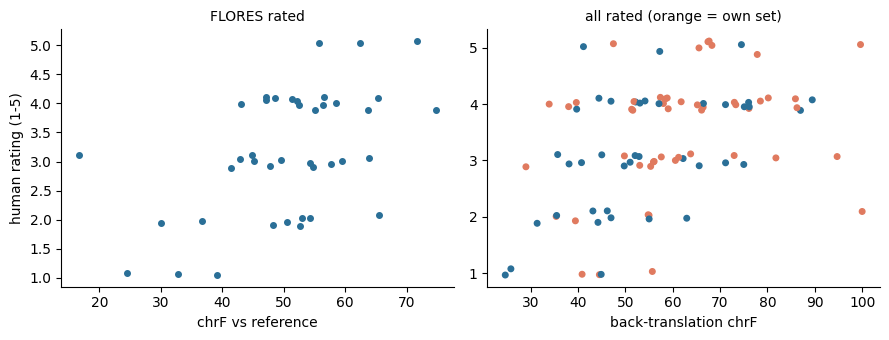

In [17]:
def flag(df, tau):
    return (df["hard"].fillna("") != "") | (df["bt_chrf"] < tau)

def scores(df, flags, bad):
    tp = int((flags & bad).sum()); fp = int((flags & ~bad).sum())
    fn = int((~flags & bad).sum()); tn = int((~flags & ~bad).sum())
    return {"n": len(df), "bad": int(bad.sum()), "caught_bad": tp, "missed_bad": fn,
            "false_alarms": fp, "good_not_flagged": tn,
            "recall_bad": round(tp / max(tp + fn, 1), 3),
            "false_alarm_rate": round(fp / max(fp + tn, 1), 3),
            "precision": round(tp / max(tp + fp, 1), 3) if tp + fp else None}

def f1(df, tau, bad):
    fl_ = flag(df, tau); tp = (fl_ & bad).sum(); fp = (fl_ & ~bad).sum(); fn = (~fl_ & bad).sum()
    return 2 * tp / max(2 * tp + fp + fn, 1)

def run_eval(col, tag, who):
    d = ev.copy(); d["r"] = d[col]
    fl = d.dropna(subset=["ref_chrf"])
    corr_rows = []
    r_s = spearmanr(fl["r"], fl["ref_chrf"]); r_p = pearsonr(fl["r"], fl["ref_chrf"])
    corr_rows.append({"metric": "chrF vs Kazakh reference", "subset": "FLORES rated", "n": len(fl),
                      "spearman": round(r_s[0], 3), "spearman_p": r_s[1], "pearson": round(r_p[0], 3)})
    for name, sub in [("all rated", d), ("own set", d[d["src_type"] != "flores"]), ("FLORES rated", fl)]:
        r_s = spearmanr(sub["r"], sub["bt_chrf"]); r_p = pearsonr(sub["r"], sub["bt_chrf"])
        corr_rows.append({"metric": "back-translation chrF (no reference)", "subset": name, "n": len(sub),
                          "spearman": round(r_s[0], 3), "spearman_p": r_s[1], "pearson": round(r_p[0], 3)})
    corr = pd.DataFrame(corr_rows); corr.to_csv(f"results/rating_vs_chrf_correlation{tag}.csv", index=False)
    print(f"--- {who}: correlation"); display(corr)

    perm = np.random.default_rng(2026).permutation(len(d))
    calib, test = d.iloc[perm[: len(d) // 2]], d.iloc[perm[len(d) // 2:]]
    out_rows, thresholds = [], {}
    for cut in (3, 2):
        bad_c, bad_t = calib["r"] <= cut, test["r"] <= cut
        grid = sorted(set(np.round(calib["bt_chrf"], 1)) | {0.0, 101.0})
        best = max(grid, key=lambda t: (f1(calib, t, bad_c), -t))  # ties -> lower threshold (fewer alarms)
        thresholds[f"bad_if_rating_le_{cut}"] = float(best)
        for system, flags in [("always trust (baseline)", pd.Series(False, index=test.index)),
                              ("hard checks only", flag(test, -1)),
                              (f"Senim: hard checks + back-translation < {best:.1f}", flag(test, best))]:
            out_rows.append({"bad_definition": f"rating <= {cut}", "split": "test", "system": system,
                             **scores(test, flags, bad_t)})
    trust_eval = pd.DataFrame(out_rows); trust_eval.to_csv(f"results/trust_check_eval{tag}.csv", index=False)
    json.dump({"rater": who, "bt_chrf_threshold": thresholds["bad_if_rating_le_3"], "chosen_on": "calibration half of data/ratings.csv",
               "bad_definition": "rating <= 3", "all": thresholds, "n_calibration": len(calib), "n_test": len(test)},
              open(f"results/threshold{tag}.json", "w"), indent=2)
    print(f"--- {who}: trust check on the test half; thresholds chosen on calibration:", thresholds); display(trust_eval)
    return d, fl

if ratings_filled():
    ev_h, fl_h = run_eval("rating", "", "human (author)")
    run_eval("llm", "_llm", "LLM judge (Claude)")

    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
    jit = np.random.default_rng(0).uniform(-0.12, 0.12, len(ev_h))
    axes[0].scatter(fl_h["ref_chrf"], fl_h["rating"] + jit[:len(fl_h)], s=16, color="#2a6f97")
    axes[0].set_xlabel("chrF vs reference"); axes[0].set_ylabel("human rating (1-5)"); axes[0].set_title("FLORES rated", fontsize=10)
    axes[1].scatter(ev_h["bt_chrf"], ev_h["rating"] + jit, s=16, c=np.where(ev_h["src_type"] == "flores", "#2a6f97", "#e07a5f"))
    axes[1].set_xlabel("back-translation chrF"); axes[1].set_title("all rated (orange = own set)", fontsize=10)
    for a in axes: a.spines[["top", "right"]].set_visible(False)
    plt.tight_layout(); plt.savefig("results/rating_vs_chrf.png", dpi=150); plt.show()

## 9. Senim v2: a smarter trust check

What v1 missed (from the human ratings): flipped negations, wrong words, and cases where the back-translation "repairs" the error.
v2 adds four signals and combines them:

| signal | idea |
|---|---|
| `neg_flag` | the number of negations ("not", "never", "without"… vs Kazakh "емес", "жоқ", verb suffix -ма/-ме) differs |
| `bt_big_chrf` | back-translation by a **different, bigger** model (NLLB 1.3B), so it is less likely to "repair" the 600M model's error |
| `agree_chrf` | chrF between the 600M translation and an independent 1.3B translation: if two models disagree, be careful |
| `labse` | LaBSE cosine similarity between the English source and the Kazakh translation (meaning, no back-translation) |

plus v1's `bt_chrf` and `hard_flag`. A logistic regression combines them.

**Rules, fixed before running this section:** same split as before (seed 2026); the model and its alarm threshold are fitted on the calibration half only; the test half is used once.
The test half had already been looked at for v1, and the negation idea came from errors seen across the whole rated set, so we also report **cross-validation over all 90** (5 folds × 20 repeats), which does not depend on one split.
The translations shown to the user still come from the 600M model, because those are the ones the human rated.

In [18]:
import time
t0 = time.time()
fl_sig = pd.DataFrame(senim.v2_signals(flores["eng_Latn"].tolist(), flores["mt_kaz_Cyrl"].tolist()))
own_sig = pd.DataFrame(senim.v2_signals(own["text_en"].tolist(), own["mt_kaz"].tolist())) if len(own) else pd.DataFrame()
print(f"v2 signals computed in {time.time() - t0:.0f}s")

# Is the bigger model a better translator? (FLORES, corpus chrF)
rows = []
for code_, name in LANGS.items():
    hyp_big = fl_sig["mt_big"].tolist() if code_ == "kaz_Cyrl" else senim.translate(flores["eng_Latn"].tolist(), "eng_Latn", code_, model_name=senim.BIG_MODEL_NAME)
    big = sacrebleu.corpus_chrf(hyp_big, [flores[code_].tolist()]).score
    small = float(chrf_table.loc[chrf_table["code"] == code_, "chrF_NLLB"].iloc[0])
    rows.append({"language": name, "n": len(flores), "chrF_600M": round(small, 1), "chrF_1.3B": round(big, 1)})
chrf_v2 = pd.DataFrame(rows); chrf_v2.to_csv("results/v2_chrf_600m_vs_1p3b.csv", index=False); display(chrf_v2)

# How noisy is the negation check on PERFECT translations? (professional FLORES references)
ref_counts = [senim.negation_counts(s_, r_) for s_, r_ in zip(flores["eng_Latn"], flores["kaz_Cyrl"])]
neg_ref_fp = sum(a != b for a, b in ref_counts)
print(f"negation check fires on {neg_ref_fp} of {len(flores)} professional reference translations (false-alarm floor)")

config.json:   0%|          | 0.00/808 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/3.55k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 5.48GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1016 [00:00<?, ?it/s]

... (18 outputs left out)

2_Dense/model.safetensors: downloading bytes:           |  0.00B            

v2 signals computed in 345s


,language,n,chrF_600M,chrF_1.3B
0,Kazakh,150,52.1,53.9
1,Russian,150,56.0,58.9
2,French,150,69.2,72.7


negation check fires on 19 of 150 professional reference translations (false-alarm floor)


In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold

if ratings_filled():
    sig = pd.concat([
        own_sig.assign(id="own_" + own["id"].astype(str).values, src_type=own["type"].values) if len(own) else pd.DataFrame(),
        fl_sig.assign(id="flores_" + flores["id"].astype(str).values, src_type="flores"),
    ], ignore_index=True)
    d2 = ratings[["id", "rating", "llm"]].merge(sig, on="id", how="left")
    F = senim.V2_FEATURES
    X = d2[F].astype(float).values
    d2["v1_score"] = d2["hard_flag"] * 1000 - d2["bt_chrf"]   # v1 ranking: hard flag first, then low back-translation chrF

    # 1) Each signal alone: ROC AUC over all 90 (no threshold, no fitting). Higher = better at ranking bad above good.
    auc_rows = []
    for cut in (3, 2):
        y = (d2["rating"] <= cut).astype(int).values
        for name, score in [("v1 (hard checks + back-translation)", d2["v1_score"]), ("back-translation chrF (600M)", -d2["bt_chrf"]),
                            ("back-translation chrF (1.3B)", -d2["bt_big_chrf"]), ("agreement with 1.3B", -d2["agree_chrf"]),
                            ("LaBSE similarity", -d2["labse"]), ("hard checks", d2["hard_flag"]), ("negation check", d2["neg_flag"])]:
            auc_rows.append({"bad_definition": f"rating <= {cut}", "signal": name, "n": len(d2), "bad": int(y.sum()), "auc": round(roc_auc_score(y, score), 3)})
    auc_tab = pd.DataFrame(auc_rows); auc_tab.to_csv("results/v2_signal_auc.csv", index=False); display(auc_tab)

    # 2) Cross-validated AUC of the combined model vs v1 (all 90, 5 folds x 20 repeats)
    cv_rows = []
    for cut in (3, 2):
        y = (d2["rating"] <= cut).astype(int).values
        rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=20, random_state=2026)
        a_v1, a_v2 = [], []
        for tr, te in rskf.split(X, y):
            sc = StandardScaler().fit(X[tr]); lr = LogisticRegression(C=1.0, max_iter=1000).fit(sc.transform(X[tr]), y[tr])
            a_v2.append(roc_auc_score(y[te], lr.predict_proba(sc.transform(X[te]))[:, 1]))
            a_v1.append(roc_auc_score(y[te], d2["v1_score"].values[te]))
        cv_rows.append({"bad_definition": f"rating <= {cut}", "auc_v1_mean": round(np.mean(a_v1), 3), "auc_v1_sd": round(np.std(a_v1), 3),
                        "auc_v2_mean": round(np.mean(a_v2), 3), "auc_v2_sd": round(np.std(a_v2), 3),
                        "v2_better_in_share_of_folds": round(np.mean(np.array(a_v2) > np.array(a_v1)), 3)})
    cv_tab = pd.DataFrame(cv_rows); cv_tab.to_csv("results/v2_cv_auc.csv", index=False); display(cv_tab)

,bad_definition,signal,n,bad,auc
0,rating <= 3,v1 (hard checks + back-translation),90,44,0.715
1,rating <= 3,back-translation chrF (600M),90,44,0.708
2,rating <= 3,back-translation chrF (1.3B),90,44,0.678
3,rating <= 3,agreement with 1.3B,90,44,0.676
4,rating <= 3,LaBSE similarity,90,44,0.673
5,rating <= 3,hard checks,90,44,0.511
6,rating <= 3,negation check,90,44,0.548
7,rating <= 2,v1 (hard checks + back-translation),90,19,0.803
8,rating <= 2,back-translation chrF (600M),90,19,0.784
9,rating <= 2,back-translation chrF (1.3B),90,19,0.778


,bad_definition,auc_v1_mean,auc_v1_sd,auc_v2_mean,auc_v2_sd,v2_better_in_share_of_folds
0,rating <= 3,0.715,0.097,0.684,0.108,0.41
1,rating <= 2,0.806,0.130,0.733,0.141,0.19


,bad_definition,split,system,n,bad,caught_bad,missed_bad,false_alarms,good_not_flagged,recall_bad,false_alarm_rate,precision,auc
0,rating <= 3,test,always trust (baseline),45,25,0.0,25.0,0.0,20.0,0.000,0.000,NaN,NaN
1,rating <= 3,test,v1: hard checks + back-translation,45,25,19.0,6.0,13.0,7.0,0.760,0.650,0.594,NaN
2,rating <= 3,test,v1 + negation check,45,25,21.0,4.0,14.0,6.0,0.840,0.700,0.600,NaN
3,rating <= 3,test,v2: combined model (p >= 0.396),45,25,16.0,9.0,10.0,10.0,0.640,0.500,0.615,NaN
4,rating <= 3,test,v2 ranking quality (AUC),45,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.592
5,rating <= 2,test,always trust (baseline),45,8,0.0,8.0,0.0,37.0,0.000,0.000,NaN,NaN
6,rating <= 2,test,v1: hard checks + back-translation,45,8,6.0,2.0,9.0,28.0,0.750,0.243,0.400,NaN
7,rating <= 2,test,v1 + negation check,45,8,7.0,1.0,14.0,23.0,0.875,0.378,0.333,NaN
8,rating <= 2,test,v2: combined model (p >= 0.581),45,8,5.0,3.0,14.0,23.0,0.625,0.378,0.263,NaN
9,rating <= 2,test,v2 ranking quality (AUC),45,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.709


,feature,coef_standardized
0,bt_chrf,-1.168
1,bt_big_chrf,-0.029
2,agree_chrf,-0.450
3,labse,-0.600
4,hard_flag,0.000
5,neg_flag,0.604


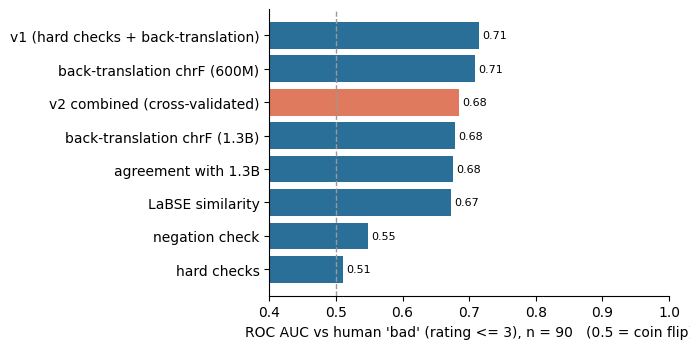

In [20]:
if ratings_filled():
    perm = np.random.default_rng(2026).permutation(len(d2))   # same split as v1
    ci, ti = perm[: len(d2) // 2], perm[len(d2) // 2:]
    calib2, test2 = d2.iloc[ci], d2.iloc[ti]
    y_c3 = (calib2["rating"] <= 3).astype(int).values
    sc = StandardScaler().fit(calib2[F].astype(float).values)
    lr = LogisticRegression(C=1.0, max_iter=1000).fit(sc.transform(calib2[F].astype(float).values), y_c3)
    p_c = lr.predict_proba(sc.transform(calib2[F].astype(float).values))[:, 1]
    p_t = lr.predict_proba(sc.transform(test2[F].astype(float).values))[:, 1]

    def best_thr(p, y):
        cands = sorted(set(np.round(p, 3)) | {0.0, 1.01})
        f1s = lambda t: (2 * ((p >= t) & (y == 1)).sum()) / max(2 * ((p >= t) & (y == 1)).sum() + ((p >= t) & (y == 0)).sum() + ((p < t) & (y == 1)).sum(), 1)
        return max(cands, key=lambda t: (f1s(t), t))   # ties -> higher threshold (fewer alarms)

    v1_thr = json.load(open("results/threshold.json"))["all"]
    rows2, thr2 = [], {}
    for cut in (3, 2):
        y_c, y_t = (calib2["rating"] <= cut).values, (test2["rating"] <= cut).values
        t_ = best_thr(p_c, y_c.astype(int)); thr2[f"bad_if_rating_le_{cut}"] = float(t_)
        v1_flags = (test2["hard_flag"] > 0) | (test2["bt_chrf"] < v1_thr[f"bad_if_rating_le_{cut}"])
        for system, flags in [("always trust (baseline)", pd.Series(False, index=test2.index)),
                              ("v1: hard checks + back-translation", v1_flags),
                              ("v1 + negation check", v1_flags | (test2["neg_flag"] > 0)),
                              (f"v2: combined model (p >= {t_:.3f})", pd.Series(p_t >= t_, index=test2.index))]:
            rows2.append({"bad_definition": f"rating <= {cut}", "split": "test", "system": system, **scores(test2, flags, pd.Series(y_t, index=test2.index))})
        rows2.append({"bad_definition": f"rating <= {cut}", "split": "test", "system": "v2 ranking quality (AUC)", "n": len(test2),
                      "bad": int(y_t.sum()), "auc": round(roc_auc_score(y_t, p_t), 3)})
    trust_v2 = pd.DataFrame(rows2); trust_v2.to_csv("results/v2_trust_check_eval.csv", index=False); display(trust_v2)

    coef = pd.DataFrame({"feature": F, "coef_standardized": lr.coef_[0].round(3)}); coef.to_csv("results/v2_model_coefficients.csv", index=False); display(coef)
    json.dump({"features": F, "coef": lr.coef_[0].tolist(), "intercept": float(lr.intercept_[0]),
               "mean": sc.mean_.tolist(), "std": sc.scale_.tolist(), "threshold": thr2["bad_if_rating_le_3"], "all_thresholds": thr2,
               "trained_on": "calibration half of data/ratings.csv (human ratings, bad = rating <= 3)", "n_train": len(calib2)},
              open("results/trust_model_v2.json", "w"), indent=2)

    fig, ax = plt.subplots(figsize=(7, 3.6))
    a3 = auc_tab[auc_tab["bad_definition"] == "rating <= 3"].set_index("signal")["auc"]
    a3 = pd.concat([a3, pd.Series({"v2 combined (cross-validated)": float(cv_tab.loc[0, "auc_v2_mean"])})]).sort_values()
    ax.barh(a3.index, a3.values, color=["#e07a5f" if "v2" in i else "#2a6f97" for i in a3.index])
    ax.axvline(0.5, color="#999", ls="--", lw=1); ax.set_xlim(0.4, 1.0)
    for i, v in enumerate(a3.values): ax.text(v + 0.005, i, f"{v:.2f}", va="center", fontsize=8)
    ax.set_xlabel("ROC AUC vs human 'bad' (rating <= 3), n = 90   (0.5 = coin flip)")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout(); plt.savefig("results/v2_signal_auc.png", dpi=150); plt.show()

## 10. Text summary of all results

In [21]:
import glob
for f in ["results/chrf_by_language.csv", "results/worst5_kaz.csv", "results/human_vs_llm_agreement.csv", "results/human_vs_llm_confusion.csv",
          "results/rating_vs_chrf_correlation.csv", "results/trust_check_eval.csv", "results/threshold.json",
          "results/rating_vs_chrf_correlation_llm.csv", "results/trust_check_eval_llm.csv", "results/threshold_llm.json",
          "results/v2_chrf_600m_vs_1p3b.csv", "results/v2_signal_auc.csv", "results/v2_cv_auc.csv", "results/v2_trust_check_eval.csv",
          "results/v2_model_coefficients.csv", "results/trust_model_v2.json"]:
    if os.path.exists(f):
        print(f"===== {f}"); print(open(f, encoding="utf-8").read())
print(f"Spearman(back-translation chrF, reference chrF), FLORES kaz n={len(flores)}: {rho:.3f} (p={p:.1e})")
print("FLORES sentences flagged by hard checks:", int((flores["hard_check_reasons"] != "").sum()), "of", len(flores))
if len(own):
    print("own sentences flagged by hard checks:", int((own["hard_check_reasons"] != "").sum()), "of", len(own))
    print("own set mean back-translation chrF:", round(own["bt_chrf"].mean(), 1), "| FLORES:", round(flores["bt_chrf"].mean(), 1))
if "neg_ref_fp" in globals():
    print(f"negation check on professional references: fires on {neg_ref_fp} of {len(flores)}")
    if ratings_filled():
        print("negation check on rated translations: fires on", int(d2["neg_flag"].sum()), "of", len(d2),
              "| of these rated bad (<=3) by human:", int(((d2["neg_flag"] > 0) & (d2["rating"] <= 3)).sum()),
              "| serious (<=2):", int(((d2["neg_flag"] > 0) & (d2["rating"] <= 2)).sum()))

===== results/chrf_by_language.csv
language,code,n,chrF_NLLB,chrF_baseline_english
Kazakh,kaz_Cyrl,150,52.1,1.4
Russian,rus_Cyrl,150,56.0,1.0
French,fra_Latn,150,69.2,25.5

===== results/worst5_kaz.csv
id,source_en,reference_kk,nllb_kk,chrf_kaz
569,"Through the night between 150 and 200 copies were made, now known as ""Dunlap broadsides"".","Бір түн ішінде 150-ден 200-ге дейін көшірмелер жасалып, олар қазір «Dunlap broadsides» ретінде белгілі.","Түн бойы 150 - 200 дана жасалды, қазір ""Дунлап еншілері"" деп аталады.",16.70382486056568
177,"The final score was a one-point victory, 21 to 20, ending the All Blacks' 15 game winning streak.","Қорытынды есеп 21-20 болып, бір ұпайлық айырмашылық болды, сонымен қатар ""All Blacks"" 15 ойындық жеңіз сериясын аяқтады.","Соңғы ұпай - бір ұпай жеңісі, 21 - 20, ""Блэкс"" командасының 15 ойын жеңіске жетті.",18.992691759461398
302,"Around 60 cases of malfunctioning iPods overheating have been reported, causing a total of six fires and leaving four p

## 11. Save everything

In [22]:
import shutil
print(sorted(os.listdir("results")))
if IN_COLAB:
    shutil.make_archive("/content/senim_results", "zip", "results")
    print("zip: /content/senim_results.zip")

['bt_vs_reference_chrf.png', 'chrf_by_language.csv', 'chrf_by_language.png', 'flores_translations.csv', 'human_vs_llm_agreement.csv', 'human_vs_llm_confusion.csv', 'own_set_translations.csv', 'rating_vs_chrf.png', 'rating_vs_chrf_correlation.csv', 'rating_vs_chrf_correlation_llm.csv', 'ratings_view.xlsx', 'threshold.json', 'threshold_llm.json', 'trust_check_eval.csv', 'trust_check_eval_llm.csv', 'trust_model_v2.json', 'v2_chrf_600m_vs_1p3b.csv', 'v2_cv_auc.csv', 'v2_model_coefficients.csv', 'v2_signal_auc.csv', 'v2_signal_auc.png', 'v2_trust_check_eval.csv', 'worst5_kaz.csv']
zip: /content/senim_results.zip
